# Q1 - Dataset description and EDA

**Dataset:** MARCO (MAchine Recognition of Crystallization Outcomes), University at Buffalo
Center for Computational Research - https://marco.ccr.buffalo.edu

**Licence:** CC BY 4.0.

**What we actually have:** 15 TFRecord shards downloaded via `scripts/download_extract.py`
(14,367 images), split once via `scripts/make_splits.py` into `data/splits.csv`
(train/val/test, grouped by drop to avoid leakage - see the Leakage checks section below).

**Task:** 4-class image classification - Clear, Crystals, Precipitate, Other. Crystals is the
decision-relevant minority class.

**Test isolation (CLAUDE.md rule 2):** the test split is read only by `scripts/final_eval.py`.
Everything in this notebook below the split-size table uses train+val only - test images are
never opened and no statistic here is computed from test.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Fixed class order and colour, used in every chart below (never cycled per-chart).
CLASS_ORDER = ["Clear", "Crystals", "Other", "Precipitate"]
CLASS_COLORS = {
    "Clear": "#0072B2",
    "Crystals": "#D55E00",
    "Precipitate": "#E69F00",
    "Other": "#999999",
}

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [2]:
splits = pd.read_csv(DATA_DIR / "splits.csv")
print(splits["split"].value_counts())

# Everything below this point uses train+val only - test is excluded (rule 2).
analysis_df = splits[splits["split"] != "test"].copy()
n_test = (splits["split"] == "test").sum()
print(f"\nEDA uses {len(analysis_df)} train+val images; {n_test} test images are excluded.") 

split
train    10261
val       2053
test      2053
Name: count, dtype: int64

EDA uses 12314 train+val images; 2053 test images are excluded.


In [3]:
splits.head()

,image_id,filename,path,label,source,group_key,split
0,396612,X0000039760279200409281034.png,raw/Clear/X0000039760279200409281034.png,Clear,2,single_396612,val
1,286612,folderID125_plateID3125_batchID18048_wellNum22...,raw/Precipitate/folderID125_plateID3125_batchI...,Precipitate,3,plate3125well22,train
2,421709,X0000042171126200411151543.png,raw/Precipitate/X0000042171126200411151543.png,Precipitate,2,single_421709,train
3,90089,folderID281_plateID1281_batchID4174_wellNum16_...,raw/Clear/folderID281_plateID1281_batchID4174_...,Clear,3,plate1281well16,test
4,296118,folderID511_plateID3511_batchID20741_wellNum58...,raw/Precipitate/folderID511_plateID3511_batchI...,Precipitate,3,plate3511well58,train


## Class distribution (train + val)

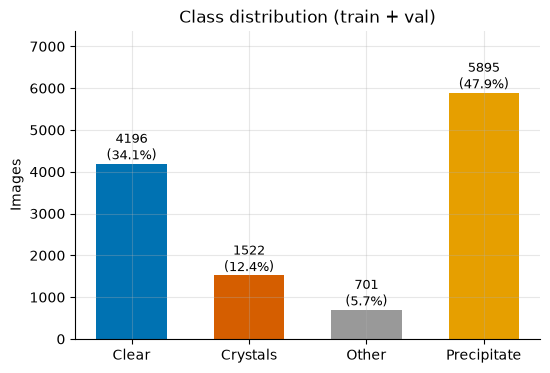

label
Clear          4196
Crystals       1522
Other           701
Precipitate    5895
Name: count, dtype: int64

In [4]:
class_counts = analysis_df["label"].value_counts().reindex(CLASS_ORDER)
class_pct = class_counts / class_counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASS_ORDER, class_counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER], width=0.6)
for bar, count, pct in zip(bars, class_counts.values, class_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Images")
ax.set_title("Class distribution (train + val)")
ax.set_ylim(0, class_counts.max() * 1.25)
fig.savefig(FIGURES_DIR / "q1_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

class_counts

## Source institution distribution (train + val)

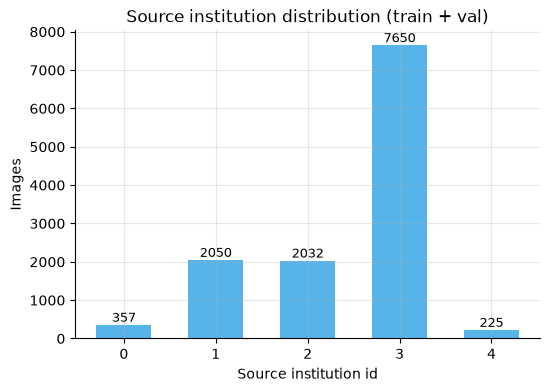

source
0     357
1    2050
2    2032
3    7650
4     225
Name: count, dtype: int64

In [5]:
source_counts = analysis_df["source"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(source_counts.index.astype(str), source_counts.values, color="#56B4E9", width=0.6)
for i, count in enumerate(source_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Source institution id")
ax.set_ylabel("Images")
ax.set_title("Source institution distribution (train + val)")
fig.savefig(FIGURES_DIR / "q1_source_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

source_counts

## Class composition by source institution

Does the class mix differ depending on which institution imaged the plate?

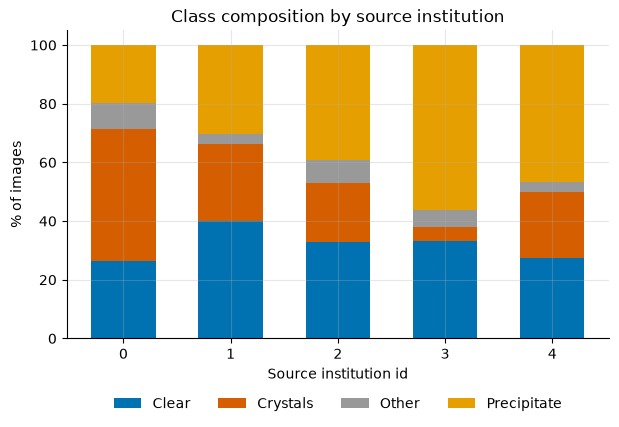

label,Clear,Crystals,Other,Precipitate
source,,,,
0,26.3,45.1,9.0,19.6
1,40.1,26.1,3.4,30.3
2,32.9,20.0,7.9,39.3
3,33.3,4.8,5.6,56.2
4,27.6,22.2,3.6,46.7


In [6]:
comp = pd.crosstab(analysis_df["source"], analysis_df["label"], normalize="index")[CLASS_ORDER] * 100

fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(comp))
for cls in CLASS_ORDER:
    ax.bar(comp.index.astype(str), comp[cls], bottom=bottom, color=CLASS_COLORS[cls], label=cls, width=0.6)
    bottom += comp[cls].values
ax.set_xlabel("Source institution id")
ax.set_ylabel("% of images")
ax.set_title("Class composition by source institution")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
fig.savefig(FIGURES_DIR / "q1_class_composition_by_source.png", dpi=150, bbox_inches="tight")
plt.show()

comp.round(1)

## Image size and quality checks

In [7]:
sample_df = analysis_df.sample(n=min(500, len(analysis_df)), random_state=42)

dims = []
for p in sample_df["path"]:
    with Image.open(DATA_DIR / p) as img:
        dims.append(img.size)  # (width, height)

dims_df = pd.DataFrame(dims, columns=["width", "height"])
print(f"sampled {len(dims_df)} images (seed=42)")
print(dims_df.describe())
print("\nmost common (width, height) pairs:")
dims_df.value_counts().head(10)

sampled 500 images (seed=42)
             width       height
count   500.000000   500.000000
mean   1240.512000   956.656000
std     385.841269   324.415555
min     632.000000   504.000000
25%    1280.000000   960.000000
50%    1280.000000   960.000000
75%    1280.000000   960.000000
max    2448.000000  2048.000000

most common (width, height) pairs:


width  height
1280   960       348
632    504        81
1224   1024       41
2448   2048       30
Name: count, dtype: int64

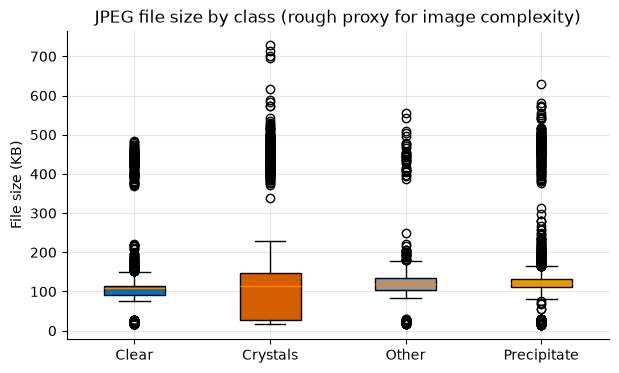

In [8]:
manifest = pd.read_csv(DATA_DIR / "raw" / "manifest.csv")
analysis_with_size = analysis_df.merge(manifest[["image_id", "n_bytes"]], on="image_id", how="left")

fig, ax = plt.subplots(figsize=(7, 4))
data_by_class = [analysis_with_size.loc[analysis_with_size["label"] == c, "n_bytes"] / 1024 for c in CLASS_ORDER]
bp = ax.boxplot(data_by_class, tick_labels=CLASS_ORDER, patch_artist=True)
for patch, cls in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[cls])
ax.set_ylabel("File size (KB)")
ax.set_title("JPEG file size by class (rough proxy for image complexity)")
fig.savefig(FIGURES_DIR / "q1_filesize_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

## Leakage checks

`scripts/make_splits.py` groups images from the same physical drop (plate+well, or a detected
near-duplicate) so no group's images cross a split boundary - see that script's docstring for
the full three-tier method. Re-verifying and summarising here for the report.

In [9]:
def group_tier(key: str) -> str:
    if key.startswith("single_"):
        return "no filename/hash group (singleton)"
    if key.startswith("hashdup_"):
        return "near-duplicate hash group (no filename info)"
    if key.startswith("plate"):
        return "plate+well filename pattern"
    return "hash+well filename pattern"

analysis_df["group_tier"] = analysis_df["group_key"].apply(group_tier)
print(analysis_df["group_tier"].value_counts())

group_sizes = analysis_df.groupby("group_key").size()
print("\ngroup size distribution:")
print(group_sizes.value_counts().sort_index())

spans = analysis_df.groupby("group_key")["split"].nunique()
assert (spans == 1).all(), "a group spans multiple splits - leakage!"
print("\nconfirmed: no group spans more than one split")

group_tier
plate+well filename pattern                     7650
no filename/hash group (singleton)              2374
hash+well filename pattern                      1807
near-duplicate hash group (no filename info)     483
Name: count, dtype: int64

group size distribution:
1     11202
2       355
3        25
4         9
5         7
6         5
7         2
12        2
14        2
16        1
20        1
23        1
25        2
51        1
Name: count, dtype: int64

confirmed: no group spans more than one split


In [10]:
big = group_sizes[group_sizes >= 12].index
print(analysis_df[analysis_df["group_key"].isin(big)]
      .groupby("group_key")
      .agg(n=("label", "size"), tier=("group_tier", "first"),
           labels=("label", lambda s: s.value_counts().to_dict())))

                                                     n  \
group_key                                                
hashdup_000000000001110000111100001111000011110...  25   
hashdup_000000000001110000111100001111100011110...  14   
hashdup_000000000001110000111100001111100011111...  16   
hashdup_000000000001110000111100001111100011111...  51   
hashdup_000000000001110000111110001111100011111...  25   
hashdup_000010000001110000111110001111100011111...  14   
hashdup_000110000011110001111110011111100111111...  12   
hashdup_000110000011110001111110011111100111111...  20   
hashdup_000110000011110001111110011111100111111...  23   
hashdup_001111000111111001111110011111100111111...  12   

                                                                                            tier  \
group_key                                                                                          
hashdup_000000000001110000111100001111000011110...  near-duplicate hash group (no filename info)   
has

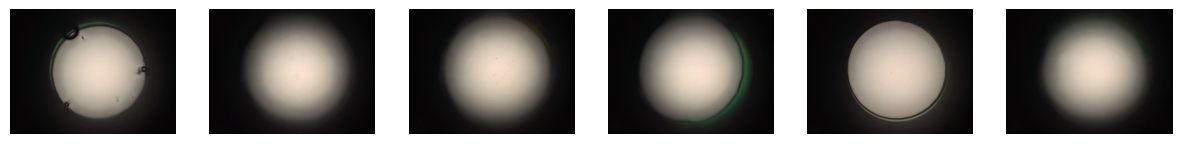

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
key = group_sizes.idxmax()   # the 51-image group
paths = analysis_df.loc[analysis_df["group_key"] == key, "path"].head(6)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, p in zip(axes, paths):
    ax.imshow(Image.open(DATA_DIR / p)); ax.axis("off")
fig.savefig(FIGURES_DIR / "q1_leakage_group_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
multi_groups = group_sizes[group_sizes > 1].index
multi_df = analysis_df[analysis_df["group_key"].isin(multi_groups)]
label_nunique = multi_df.groupby("group_key")["label"].nunique()
n_drift = (label_nunique > 1).sum()
print(f"{len(multi_groups)} groups have more than one image")
print(f"{n_drift} of them ({n_drift / len(multi_groups) * 100:.1f}%) show different labels across images "
      "within the same group - consistent with crystallisation being a kinetic process (the same "
      "well imaged again days later can look different). The split still keeps the whole group "
      "together; each group's majority label was used only to stratify the split, not as a claim "
      "that the group has one true label.")

413 groups have more than one image
58 of them (14.0%) show different labels across images within the same group - consistent with crystallisation being a kinetic process (the same well imaged again days later can look different). The split still keeps the whole group together; each group's majority label was used only to stratify the split, not as a claim that the group has one true label.


In [13]:
drift_keys = label_nunique[label_nunique > 1].index
print(multi_df[multi_df["group_key"].isin(drift_keys)]
      .groupby("group_key")["label"]
      .agg(lambda s: " / ".join(sorted(s.unique())))
      .value_counts())

label
Clear / Precipitate       28
Other / Precipitate       20
Crystals / Precipitate     4
Clear / Crystals           3
Clear / Other              2
Crystals / Other           1
Name: count, dtype: int64


**Interpretation.** The largest hash groups (up to 51 images) are all single-label and visually
generic - spot-checking the 51-image `Clear` group shows clearly different wells (different bubble
shapes/artifacts), not the same physical drop imaged repeatedly. The coarse average-hash collides
on visually simple images (an empty well is just a bright circle on a dark background), so the
`hashdup_` tier over-groups for simple classes rather than finding true duplicates. This is **safe,
not dangerous**, for the leakage rule - grouping unrelated images together only wastes some split
flexibility, it never lets a true duplicate land on both sides of a split. But it means `hashdup_`
groups should be read as "visually generic, merged conservatively," not literally "same drop."

The label-drift pairs are also informative: `Clear`/`Precipitate` and `Other`/`Precipitate` make up
most of the drift (28 and 20 of 58 drifting groups) - consistent with precipitation being a common
outcome a drop settles into over time, rather than random label noise.

## FP/FN consequences and metric justification

A false negative (a missed Crystals image) can lose a hit from scarce, expensive protein - the
sample may not be recoverable. A false positive costs a crystallographer a few minutes of manual
inspection. These costs are highly asymmetric, and Crystals is the minority class, so accuracy is
misleading as a headline metric - a classifier can score well on accuracy while being useless for
the actual decision. A concrete illustration:

In [14]:
majority_class = analysis_df["label"].value_counts().idxmax()
majority_acc = (analysis_df["label"] == majority_class).mean() * 100

print(f"Always predicting '{majority_class}': accuracy = {majority_acc:.1f}%, "
      f"but Crystals recall = 0% - every crystal hit would be missed, despite a "
      f"seemingly OK accuracy score.")

Always predicting 'Precipitate': accuracy = 47.9%, but Crystals recall = 0% - every crystal hit would be missed, despite a seemingly OK accuracy score.


**Primary metric:** recall on Crystals at a fixed minimum precision (`P_MIN`), with PR-AUC for
Crystals as a supporting metric. `P_MIN` itself is still TBD - fixing a sensible value needs an
actual validation PR curve from a trained model, which doesn't exist yet at the EDA stage. The
qualitative case for recall-at-fixed-precision over accuracy is established above; the precise
`P_MIN` value will be set once the classical baseline gives us a first PR curve to look at.

## Three findings that constrain modelling

1. **Crystals is a real minority class (~12% of train+val)**, and the cost of missing one is far
   higher than a false alarm. This rules out accuracy as the headline metric and means the loss
   function/sampling strategy needs to account for the imbalance directly (e.g. class weighting),
   not rely on the model discovering it unaided.
2. **Class mix varies sharply by source institution.** Source 3 (62% of all data) has only 4.8%
   Crystals, while source 0 has 45.1% Crystals - a 9x swing. Since one institution dominates the
   pool, a model could end up implicitly tuned to that institution's imaging style and
   under-perform on the others. This directly bears on the web app's stated limitation about
   unseen imagers (Q4) and suggests checking per-source performance during error analysis (Q3),
   not just aggregate metrics.
3. **Image dimensions are not standardised.** A 500-image sample spans 632x504 up to 2448x2048,
   with `1280x960` as the dominant but not universal size (70% of the sample). This constrains
   preprocessing - an explicit, documented resize/aspect-ratio strategy is needed rather than an
   assumption that every image already arrives at a fixed input size.